# 02 · Migration network

**Question:** where did chemists move, and which countries gained or lost talent?

**Method** (`chemkg.migration`)
- A migration edge *origin → destination* needs evidence that a person was tied to two territorially distinct countries. Territory sets come from notebook 01, so Russian Empire → Soviet Union counts as one place.
- Direction comes from place of birth (P19 → current country P17):
  1. The birthplace is inside one citizenship → that citizenship is the origin.
  2. The birthplace is outside every citizenship → the birthplace country is the origin (e.g. born in Hungary, US citizen only).
  3. No birthplace → an undirected corridor, reported but not drawn.
- **Border shifts.** A birthplace's *current* country can differ from the country that held it at birth (Breslau, now Wrocław). For known border pairs, births before the shift year are labelled `border_shift` and excluded.
- Eras are 25-year *birth* cohorts.

**Assumptions:** citizenship is a proxy for where people worked, and moves without naturalisation are invisible. Dual citizenship from birth looks like migration.

In [1]:
import json, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from chemkg.data import load, analysable
from chemkg import countries
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
ds = load()
P, A = ds.people, analysable(ds.people)
NAMES = countries.load_iso3().set_index("iso3").name.to_dict()
print(f"{len(P):,} people, {len(A):,} analysable; enrichment loaded: {ds.enriched}")

11,903 people, 11,860 analysable; enrichment loaded: True


In [2]:
from chemkg import migration
edges = migration.build_edges(ds)
mig = migration.summarise(edges)
pd.Series(mig["method_counts"]).rename("edges")

birthplace_outside_citizenship    693
birthplace_in_citizenship         516
border_shift                      196
undirected                         67
Name: edges, dtype: int64

### Top corridors (directed)

In [3]:
cor = mig["corridors"].assign(origin=lambda d: d.origin.map(NAMES), dest=lambda d: d.dest.map(NAMES))
cor.head(20)

,origin,dest,n
115,Germany,United States,70
174,United Kingdom,United States,58
30,Austria,United States,34
337,Russia,United States,30
76,China,United States,30
57,Canada,United States,29
307,Poland,United States,27
159,United Kingdom,Canada,27
211,India,United States,25
105,Germany,United Kingdom,20


### Net brain gain

In [4]:
bal = mig["balance"].rename(index=NAMES)
pd.concat([bal.head(10), bal.tail(8)])

,inflow,outflow,net
United States,529,47,482
Israel,72,15,57
Canada,91,35,56
France,61,36,25
Switzerland,45,22,23
Australia,38,19,19
Sweden,22,8,14
New Zealand,19,6,13
Netherlands,12,0,12
Brazil,13,2,11


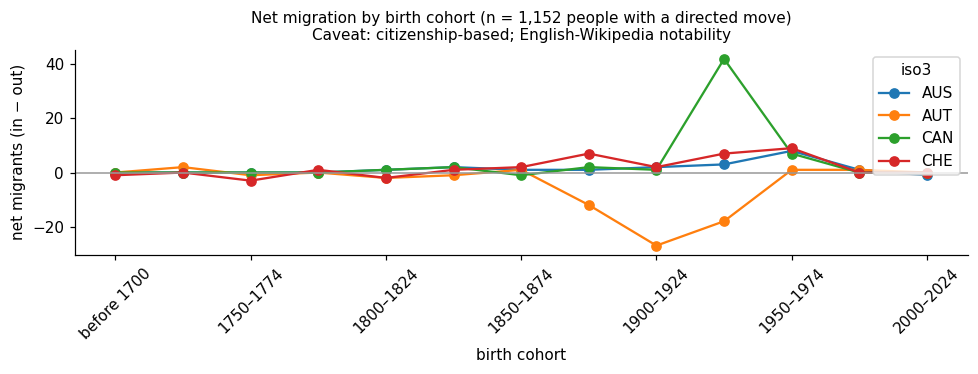

In [5]:
top = mig["balance"].head(8).index.tolist() + mig["balance"].tail(5).index.tolist()
en = mig["era_net"][mig["era_net"].iso3.isin(top)].pivot_table(index="era", columns="iso3", values="net", fill_value=0)
en = en.reindex([e for e in mig["era_order"] if e in en.index])
ax = en[["USA", "GBR", "DEU", "CAN"] if set(["USA","GBR","DEU","CAN"]) <= set(en.columns) else en.columns[:4]].plot(marker="o", figsize=(9, 3.5))
ax.axhline(0, color="#999", lw=1); ax.set_ylabel("net migrants (in − out)"); ax.set_xlabel("birth cohort")
ax.set_title(f"Net migration by birth cohort (n = {mig['n_people_directed']:,} people with a directed move)\nCaveat: citizenship-based; English-Wikipedia notability", fontsize=10)
plt.xticks(rotation=45); plt.tight_layout()

### Corridors by era

In [6]:
be = mig["by_era"].assign(corridor=lambda d: d.origin.map(NAMES) + " → " + d.dest.map(NAMES))
be.sort_values("n", ascending=False).groupby("era").head(3).sort_values(["era", "n"], ascending=[True, False])

,era,origin,dest,n,corridor
4,1725–1749,RUS,SWE,2,Russia → Sweden
3,1725–1749,FRA,GBR,2,France → United Kingdom
0,1725–1749,DEU,AUT,1,Germany → Austria
8,1750–1774,CHE,FRA,2,Switzerland → France
12,1750–1774,FIN,SWE,2,Finland → Sweden
17,1750–1774,ITA,PRT,1,Italy → Portugal
22,1775–1799,GBR,USA,1,United Kingdom → United States
21,1775–1799,FRA,USA,1,France → United States
20,1775–1799,ESP,FRA,1,Spain → France
31,1800–1824,DEU,USA,3,Germany → United States


### Reading the result
- The United States dominates inflows from the late-19th-century cohorts on. Germany → US is the largest single corridor.
- The largest net exporters are Germany, Austria, Russia, Poland and China. That fits the 1930s emigration from Central Europe, Soviet-era emigration and the post-1949 Chinese diaspora.
- Israel's positive balance reflects post-1948 immigration, mostly from Eastern Europe.
- **Limitation:** only about 1 in 10 chemists has a recorded move, and the US share is inflated by English-Wikipedia coverage.